# 04 — Protocol v1.0, Stages 3–4 (New England): nonresponse and small area estimation

## Stage 3: NR-LATE, a real nonresponse mechanism
**Response.** A take-some unit responds if its TY2023 return was filed ≤ 300 days after fiscal year end. This is
real filing behaviour: 61% of take-some units respond, but only 13% of take-all units, because large
organizations file on extension.

**Take-all units**, two pre-registered scenarios:
- **TA-follow-up:** take-all units respond with probability 0.9 (MCAR), as if intensively chased.
- **TA-late:** take-all units follow the real 300-day rule.

Take-all nonrespondents are imputed by their own last-cycle value (TA-hist-own).

**Take-some estimators**, all on respondents only:
- status quo: weighting-class (stratum) adjustment plus GREG on the F1p register;
- BMF-max twin and text model calibration, with the same weighting-class adjustment;
- propensity-score variants: frame-only propensities, and text in the propensity.

**Rule S6.** The text arm must satisfy all three, on the five variables {government grants, contributions, fundraising, volunteers, lobbying}:
- it removes ≥ 30% of the reference method's nonresponse bias on ≥ 3 of the 5 (bias-reduction fraction, BRF);
- its RRMSE ratio is ≤ 1.00;
- its coverage gap is ≥ −2 pp.

**Reference method (protocol §7.2).** For each y, the reference is the text-free method with the smallest limiting
absolute bias. The candidates run here are weighting class + HT, weighting class + GREG (the status quo), the
weighting-class BMF-max twin, and the frame-propensity twin. The limiting bias is estimated by the take-some Monte Carlo
RB at R = 1,000 (deviation D-29). The comparison against the status quo GREG is reported as a secondary.

**Pilot claim tested here (§7.2).** Calibrating to lagged size *increases* nonresponse bias for survey-only y:
abs(B(weighting class + GREG)) > abs(B(weighting class)) for government grants, contributions and fundraising.

## Stage 4: small area estimation
**Domains.** 66 unplanned domains, state × NTEE10, with 0–50 sampled units each.

**Estimators.** Each is fitted with three models: production GREG (B0), the BMF-max twin, and the text model. The two names mirror notebook 03's arms; here they are cross-fitted on the current sample, not frozen.
- **DIR:** direct (model-free).
- **MA:** model-assisted, approximately design-unbiased.
- **SYN:** synthetic.
- **FH:** Fay–Herriot composite.

**Rule S7**, for government grants and the share with government grants:
- ARRMSE(FH text) / ARRMSE(FH twin) ≤ 0.90;
- ARB not worse by more than 1 pp;
- the publishable share (domain RRMSE < 25%) up by at least 5 pp;
- fewer than 5% of domains worse by more than 10%.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
import plotstyle; plotstyle.use()
from analysis import cell_metrics, paired_re
from report import Y_LABEL
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
OUT = f"{DATA}/results/stage34_ne_v3"
RES = os.path.join(PROJ, "results", "stage34_ne_v3"); os.makedirs(RES, exist_ok=True)
S6_Y = ["y_gov_grants", "y_contrib", "y_fundraising_exp", "y_volunteers_cap10k", "y_bin_lobbying"]

## Stage 3 results

In [2]:
nr_rows, TS = [], {}
for scen in ["follow", "late"]:
    p = f"{OUT}/nr_{scen}.parquet"
    if not os.path.exists(p):
        print("missing", p); continue
    d = pd.read_parquet(p); meta = json.load(open(f"{OUT}/nr_{scen}_meta.json")); truth = meta["truth"]
    cm = cell_metrics(d, truth); cm["scenario"] = scen
    # take-some part only: remove the take-all total actually used (true or imputed) from each estimate
    ta = pd.read_parquet(f"{OUT}/nr_{scen}_ta.parquet")
    dts = d.merge(ta, on=["rep", "y"]); dts["est"] = dts.est - dts.ta_used
    truth_ts = {y: truth[y] - meta["truth_ta"][y] for y in truth}
    TS[scen] = (dts, truth_ts, d, truth)
    cts = cell_metrics(dts[["rep", "estimator", "y", "est", "var"]], truth_ts).rename(columns=lambda c: c + "_ts" if c not in ("estimator", "y") else c)
    cm = cm.merge(cts[["estimator", "y", "rb_pct_ts", "rrmse_pct_ts", "coverage_pct_ts"]], on=["estimator", "y"])
    nr_rows.append(cm)
    for col, lab in [("rb_pct", "relative bias of the total (%)"), ("rb_pct_ts", "relative bias of the take-some part (%)")]:
        t = cm.pivot(index="y", columns="estimator", values=col); t.index = [Y_LABEL.get(i, i) for i in t.index]
        print(f"\n=== TA-{scen}: {lab} ==="); display(t.round(2))
    for col, lab in [("coverage_pct", "coverage of the total (%); take-all imputation error is not in the variance"),
                     ("coverage_pct_ts", "coverage of the take-some part (%)")]:
        c = cm.pivot(index="y", columns="estimator", values=col); c.index = [Y_LABEL.get(i, i) for i in c.index]
        print(f"=== TA-{scen}: {lab} ==="); display(c.round(1))
nr = pd.concat(nr_rows) if nr_rows else pd.DataFrame()


=== TA-follow: relative bias of the total (%) ===


estimator,FULLRESP_GREG_size_cat@F1p,NR_SQ_rhg_GREG_size_cat@F1p,NR_ps_frame_MCAL_bmfmax@F1p,NR_ps_text_MCAL_bmfmax@F1p+Estar,NR_rhg_HT,NR_rhg_MCAL_bmfmax@F1p,NR_rhg_MCAL_bmfmax@F1p+Estar
Share with foreign activities,1.21,-13.61,-12.48,-11.64,-15.63,-13.51,-13.33
Share granting to individuals,0.72,1.32,2.15,0.57,-0.78,1.39,0.47
Share with gov. grants,0.09,-0.75,-0.90,-0.60,0.98,-0.78,-0.56
Share with volunteers,0.17,-0.95,-0.77,-0.54,-0.48,-0.88,-0.82
Share lobbying,0.65,-4.61,-3.92,-3.31,-10.40,-4.48,-4.32
Contributions,0.16,5.43,4.90,3.14,0.84,4.88,3.19
Employees,-0.03,-0.52,-0.54,-0.48,-4.93,-0.54,-0.55
Total expenses,0.01,-0.09,-0.11,-0.10,-5.07,-0.11,-0.11
Fundraising expenses,1.01,11.23,10.67,8.61,1.13,10.67,8.62
Government grants,0.24,8.92,7.76,5.73,2.62,8.01,5.96



=== TA-follow: relative bias of the take-some part (%) ===


estimator,FULLRESP_GREG_size_cat@F1p,NR_SQ_rhg_GREG_size_cat@F1p,NR_ps_frame_MCAL_bmfmax@F1p,NR_ps_text_MCAL_bmfmax@F1p+Estar,NR_rhg_HT,NR_rhg_MCAL_bmfmax@F1p,NR_rhg_MCAL_bmfmax@F1p+Estar
Share with foreign activities,1.34,-15.46,-14.18,-13.23,-17.75,-15.35,-15.15
Share granting to individuals,0.77,1.39,2.26,0.61,-0.79,1.46,0.51
Share with gov. grants,0.09,-0.76,-0.92,-0.61,1.00,-0.80,-0.57
Share with volunteers,0.18,-0.96,-0.78,-0.55,-0.49,-0.89,-0.83
Share lobbying,0.74,-5.25,-4.46,-3.77,-11.84,-5.10,-4.92
Contributions,1.00,13.13,11.90,7.87,2.58,11.86,7.98
Employees,-0.07,-0.98,-1.01,-0.90,-9.16,-1.01,-1.04
Total expenses,0.12,-0.18,-0.24,-0.19,-15.32,-0.24,-0.23
Fundraising expenses,1.60,19.66,18.67,15.02,1.81,18.67,15.05
Government grants,0.56,14.82,12.92,9.59,4.46,13.34,9.96


=== TA-follow: coverage of the total (%); take-all imputation error is not in the variance ===


...

estimator,FULLRESP_GREG_size_cat@F1p,NR_SQ_rhg_GREG_size_cat@F1p,NR_ps_frame_MCAL_bmfmax@F1p,NR_ps_text_MCAL_bmfmax@F1p+Estar,NR_rhg_HT,NR_rhg_MCAL_bmfmax@F1p,NR_rhg_MCAL_bmfmax@F1p+Estar
Share with foreign activities,1.34,-15.46,-14.18,-13.23,-17.75,-15.35,-15.15
Share granting to individuals,0.77,1.39,2.26,0.61,-0.79,1.46,0.51
Share with gov. grants,0.09,-0.76,-0.92,-0.61,1.00,-0.80,-0.57
Share with volunteers,0.18,-0.96,-0.78,-0.55,-0.49,-0.89,-0.83
Share lobbying,0.74,-5.25,-4.46,-3.77,-11.84,-5.10,-4.92
Contributions,1.00,13.13,11.90,7.87,2.58,11.86,7.98
Employees,-0.07,-0.98,-1.01,-0.90,-9.16,-1.01,-1.04
Total expenses,0.12,-0.18,-0.24,-0.19,-15.32,-0.24,-0.23
Fundraising expenses,1.60,19.66,18.67,15.02,1.81,18.67,15.05
Government grants,0.56,14.82,12.92,9.59,4.46,13.34,9.96


=== TA-late: coverage of the total (%); take-all imputation error is not in the variance ===


estimator,FULLRESP_GREG_size_cat@F1p,NR_SQ_rhg_GREG_size_cat@F1p,NR_ps_frame_MCAL_bmfmax@F1p,NR_ps_text_MCAL_bmfmax@F1p+Estar,NR_rhg_HT,NR_rhg_MCAL_bmfmax@F1p,NR_rhg_MCAL_bmfmax@F1p+Estar
Share with foreign activities,92.9,75.1,75.6,76.2,73.5,74.6,74.5
Share granting to individuals,93.8,92.5,91.4,91.3,92.8,92.3,91.4
Share with gov. grants,94.5,93.3,93.0,92.1,95.5,93.5,92.9
Share with volunteers,93.5,91.6,90.8,90.8,93.2,90.9,90.7
Share lobbying,93.4,84.0,84.7,86.0,81.0,84.5,84.6
Contributions,78.5,49.1,47.4,54.1,95.3,45.1,49.7
Employees,82.8,39.6,43.2,42.2,69.7,38.7,39.6
Total expenses,28.5,30.2,30.8,30.9,28.2,28.6,29.6
Fundraising expenses,83.1,56.6,58.9,61.1,94.0,55.5,56.5
Government grants,92.1,72.3,72.9,74.7,94.6,70.5,71.9


=== TA-late: coverage of the take-some part (%) ===


estimator,FULLRESP_GREG_size_cat@F1p,NR_SQ_rhg_GREG_size_cat@F1p,NR_ps_frame_MCAL_bmfmax@F1p,NR_ps_text_MCAL_bmfmax@F1p+Estar,NR_rhg_HT,NR_rhg_MCAL_bmfmax@F1p,NR_rhg_MCAL_bmfmax@F1p+Estar
Share with foreign activities,92.9,74.9,75.4,75.8,73.1,74.4,74.1
Share granting to individuals,93.8,92.5,91.6,91.2,92.8,92.3,91.4
Share with gov. grants,94.5,93.3,93.0,92.1,95.5,93.5,92.9
Share with volunteers,93.5,91.7,90.9,90.8,93.2,90.9,90.6
Share lobbying,93.4,84.0,84.7,86.0,81.0,84.5,84.6
Contributions,90.2,64.9,64.2,69.9,93.9,61.5,66.6
Employees,91.0,44.7,47.4,47.1,74.5,44.6,44.1
Total expenses,91.9,52.8,56.0,55.5,45.3,51.5,50.6
Fundraising expenses,86.8,62.2,64.3,66.1,90.9,60.3,62.6
Government grants,90.7,73.3,74.6,75.9,93.0,71.8,73.7


In [3]:
TEXT_FREE = ["NR_rhg_HT", "NR_SQ_rhg_GREG_size_cat@F1p", "NR_rhg_MCAL_bmfmax@F1p", "NR_ps_frame_MCAL_bmfmax@F1p"]

def _boot(scen, text, ref, y, B=2000, seed=0):
    """Paired replicate bootstrap, 90% intervals: BRF and RRMSE ratio (take-some), RRMSE ratio (total)."""
    dts, tts, d, tr = TS[scen]
    g = dts[dts.y == y].pivot(index="rep", columns="estimator", values="est")
    G = d[d.y == y].pivot(index="rep", columns="estimator", values="est")
    et, er = (g[text] - tts[y]).to_numpy(), (g[ref] - tts[y]).to_numpy()
    Et, Er = (G[text] - tr[y]).to_numpy(), (G[ref] - tr[y]).to_numpy()
    i = np.random.default_rng(seed).integers(0, len(et), (B, len(et)))
    brf = 1 - np.abs(et[i].mean(1)) / np.abs(er[i].mean(1))
    rr = np.sqrt((et[i] ** 2).mean(1) / (er[i] ** 2).mean(1))
    rrT = np.sqrt((Et[i] ** 2).mean(1) / (Er[i] ** 2).mean(1))
    q = lambda v: np.quantile(v, [0.05, 0.95])
    return q(brf), q(rr), q(rrT)

def s6(nr, scen, text="NR_rhg_MCAL_bmfmax@F1p+Estar", ref="protocol", gates_run=False):
    """ref='protocol': per-y text-free method with the smallest |RB| of the take-some part; ref=<name>: that method.
    Returns (table, point conditions met, formal pass). The formal pass also needs the NR1/NR2 gates (not run, D-30)."""
    m = nr[nr.scenario == scen].set_index(["estimator", "y"])
    out = []
    for y in S6_Y:
        r = min(TEXT_FREE, key=lambda e: abs(m.loc[(e, y), "rb_pct_ts"])) if ref == "protocol" else ref
        b_t, b_r = m.loc[(text, y), "rb_pct_ts"], m.loc[(r, y), "rb_pct_ts"]
        (blo, bhi), (rlo, rhi), (Rlo, Rhi) = _boot(scen, text, r, y)
        out.append({"y": Y_LABEL.get(y, y), "reference": r, "bias text % (take-some)": b_t, "bias ref %": b_r,
                    "BRF": 1 - abs(b_t) / abs(b_r) if b_r else np.nan, "BRF lo": blo, "BRF hi": bhi,
                    "RRMSE ratio (take-some)": m.loc[(text, y), "rrmse_pct_ts"] / m.loc[(r, y), "rrmse_pct_ts"], "lo": rlo, "hi": rhi,
                    "RRMSE ratio (total)": m.loc[(text, y), "rrmse_pct"] / m.loc[(r, y), "rrmse_pct"], "total lo": Rlo, "total hi": Rhi,
                    "coverage gap (pp)": m.loc[(text, y), "coverage_pct_ts"] - m.loc[(r, y), "coverage_pct_ts"]})
    t = pd.DataFrame(out)
    point_ok = ((t["BRF"] >= 0.30).sum() >= 3) and (t["RRMSE ratio (take-some)"] <= 1.0).all() \
        and (t["RRMSE ratio (total)"] <= 1.0).all() and (t["coverage gap (pp)"] >= -2).all()
    return t, point_ok, point_ok and gates_run

if len(nr):
    for scen in ["follow", "late"]:
        if not (nr.scenario == scen).any():
            continue
        for ref, lab in [("protocol", "S6 (protocol reference)"), ("NR_SQ_rhg_GREG_size_cat@F1p", "secondary: vs status quo GREG"),
                         ("NR_rhg_MCAL_bmfmax@F1p", "secondary: vs the same learner without text")]:
            t, point_ok, formal_ok = s6(nr, scen, ref=ref)
            status = "PASS" if formal_ok else ("point conditions met; not a formal pass (NR1/NR2 gates not run, D-30)" if point_ok else "FAIL")
            print(f"TA-{scen}, {lab}: {status}"); display(t.round(3))
            t.to_csv(f"{RES}/s6_{scen}_{ref.split('@')[0]}.csv", index=False)
        m = nr[nr.scenario == scen].set_index(["estimator", "y"]).rb_pct_ts
        claim = pd.DataFrame([{"y": Y_LABEL.get(y, y), "|bias| weighting class + HT %": abs(m[("NR_rhg_HT", y)]),
                               "|bias| weighting class + GREG %": abs(m[("NR_SQ_rhg_GREG_size_cat@F1p", y)])}
                              for y in ["y_gov_grants", "y_contrib", "y_fundraising_exp"]])
        claim["calibration increases bias"] = claim.iloc[:, 2] > claim.iloc[:, 1]
        print(f"TA-{scen}: pilot claim (calibrating to size increases nonresponse bias)"); display(claim.round(2))

TA-follow, S6 (protocol reference): FAIL


,y,reference,bias text % (take-some),bias ref %,BRF,BRF lo,BRF hi,RRMSE ratio (take-some),lo,hi,RRMSE ratio (total),total lo,total hi,coverage gap (pp)
0,Government grants,NR_rhg_HT,9.960,4.463,-1.231,-1.758,-0.852,1.340,1.251,1.433,1.338,1.250,1.430,-19.3
1,Contributions,NR_rhg_HT,7.981,2.580,-2.094,-2.918,-1.542,1.381,1.307,1.459,1.362,1.289,1.438,-27.3
2,Fundraising expenses,NR_rhg_HT,15.046,1.815,-7.292,-13.329,-4.991,2.038,1.900,2.187,2.039,1.902,2.186,-28.3
3,Volunteers (capped 10k),NR_rhg_HT,5.756,4.951,-0.163,-0.355,-0.014,1.108,1.072,1.147,1.108,1.072,1.147,-5.3
4,Share lobbying,NR_ps_frame_MCAL_bmfmax@F1p,-4.919,-4.460,-0.103,-0.166,-0.057,0.996,0.986,1.006,0.996,0.986,1.006,-0.1


TA-follow, secondary: vs status quo GREG: FAIL


,y,reference,bias text % (take-some),bias ref %,BRF,BRF lo,BRF hi,RRMSE ratio (take-some),lo,hi,RRMSE ratio (total),total lo,total hi,coverage gap (pp)
0,Government grants,NR_SQ_rhg_GREG_size_cat@F1p,9.960,14.823,0.328,0.279,0.378,0.827,0.797,0.857,0.827,0.797,0.858,0.4
1,Contributions,NR_SQ_rhg_GREG_size_cat@F1p,7.981,13.134,0.392,0.359,0.427,0.786,0.765,0.809,0.792,0.771,0.814,1.7
2,Fundraising expenses,NR_SQ_rhg_GREG_size_cat@F1p,15.046,19.661,0.235,0.199,0.272,0.897,0.869,0.925,0.897,0.869,0.924,0.4
3,Volunteers (capped 10k),NR_SQ_rhg_GREG_size_cat@F1p,5.756,8.585,0.329,0.263,0.410,0.994,0.979,1.008,0.994,0.979,1.008,-1.4
4,Share lobbying,NR_SQ_rhg_GREG_size_cat@F1p,-4.919,-5.253,0.064,0.030,0.102,1.007,0.998,1.015,1.007,0.998,1.015,0.6


TA-follow, secondary: vs the same learner without text: FAIL


...

,y,reference,bias text % (take-some),bias ref %,BRF,BRF lo,BRF hi,RRMSE ratio (take-some),lo,hi,RRMSE ratio (total),total lo,total hi,coverage gap (pp)
0,Government grants,NR_SQ_rhg_GREG_size_cat@F1p,9.960,14.823,0.328,0.279,0.378,0.827,0.797,0.857,0.828,0.800,0.857,0.4
1,Contributions,NR_SQ_rhg_GREG_size_cat@F1p,7.981,13.134,0.392,0.359,0.427,0.786,0.765,0.809,0.804,0.786,0.822,1.7
2,Fundraising expenses,NR_SQ_rhg_GREG_size_cat@F1p,15.046,19.661,0.235,0.199,0.272,0.897,0.869,0.925,0.897,0.871,0.921,0.4
3,Volunteers (capped 10k),NR_SQ_rhg_GREG_size_cat@F1p,5.756,8.585,0.329,0.263,0.410,0.994,0.979,1.008,0.995,0.980,1.010,-1.4
4,Share lobbying,NR_SQ_rhg_GREG_size_cat@F1p,-4.919,-5.253,0.064,0.030,0.102,1.007,0.998,1.015,1.007,0.998,1.015,0.6


TA-late, secondary: vs the same learner without text: FAIL


,y,reference,bias text % (take-some),bias ref %,BRF,BRF lo,BRF hi,RRMSE ratio (take-some),lo,hi,RRMSE ratio (total),total lo,total hi,coverage gap (pp)
0,Government grants,NR_rhg_MCAL_bmfmax@F1p,9.960,13.339,0.253,0.214,0.297,0.857,0.825,0.888,0.859,0.830,0.889,1.9
1,Contributions,NR_rhg_MCAL_bmfmax@F1p,7.981,11.859,0.327,0.295,0.359,0.837,0.819,0.856,0.848,0.834,0.864,5.1
2,Fundraising expenses,NR_rhg_MCAL_bmfmax@F1p,15.046,18.665,0.194,0.161,0.228,0.920,0.897,0.942,0.919,0.898,0.939,2.3
3,Volunteers (capped 10k),NR_rhg_MCAL_bmfmax@F1p,5.756,8.814,0.347,0.280,0.429,0.969,0.956,0.983,0.970,0.957,0.984,-0.8
4,Share lobbying,NR_rhg_MCAL_bmfmax@F1p,-4.919,-5.101,0.036,0.003,0.071,1.006,0.997,1.014,1.006,0.997,1.014,0.1


TA-late: pilot claim (calibrating to size increases nonresponse bias)


,y,|bias| weighting class + HT %,|bias| weighting class + GREG %,calibration increases bias
0,Government grants,4.46,14.82,True
1,Contributions,2.58,13.13,True
2,Fundraising expenses,1.81,19.66,True


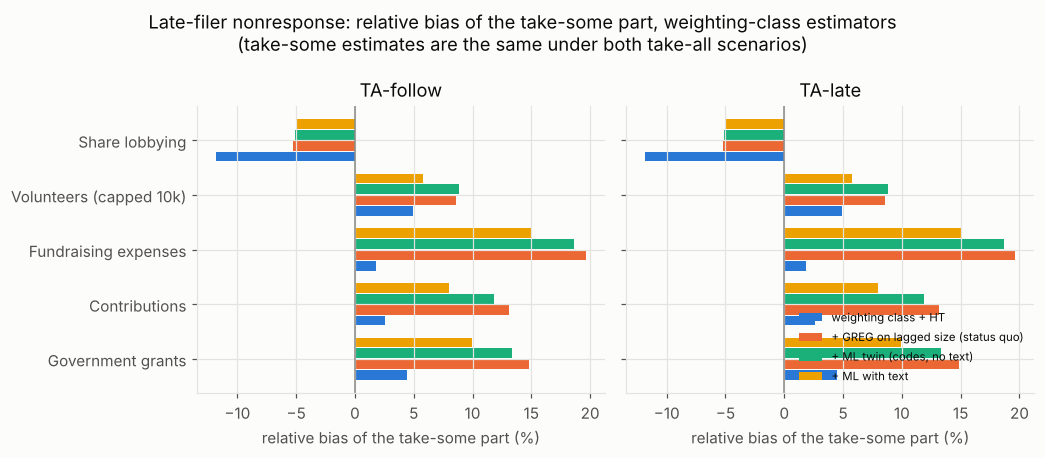

In [4]:
if len(nr):
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), sharey=True)
    arms = ["NR_rhg_HT", "NR_SQ_rhg_GREG_size_cat@F1p", "NR_rhg_MCAL_bmfmax@F1p", "NR_rhg_MCAL_bmfmax@F1p+Estar"]
    names = ["weighting class + HT", "+ GREG on lagged size (status quo)", "+ ML twin (codes, no text)", "+ ML with text"]
    for ax, scen in zip(axes, ["follow", "late"]):  # identical by construction; both shown as a check
        if not (nr.scenario == scen).any():
            continue
        m = nr[nr.scenario == scen].set_index(["estimator", "y"]).rb_pct_ts
        yy = np.arange(len(S6_Y))
        for j, (a, nm) in enumerate(zip(arms, names)):
            ax.barh(yy + (j - 1.5) * 0.2, [m[(a, y)] for y in S6_Y], height=0.18, color=plotstyle.SERIES[j], label=nm)
        ax.axvline(0, color=plotstyle.NEUTRAL, lw=1)
        ax.set_yticks(yy); ax.set_yticklabels([Y_LABEL.get(y, y) for y in S6_Y]); ax.invert_yaxis()
        ax.set_title(f"TA-{scen}"); ax.set_xlabel("relative bias of the take-some part (%)")
    axes[-1].legend(fontsize=7.5, loc="lower right")
    fig.suptitle("Late-filer nonresponse: relative bias of the take-some part, weighting-class estimators\n(take-some estimates are the same under both take-all scenarios)")
    plt.tight_layout(); plt.savefig(f"{RES}/nr_bias.png", dpi=150); plt.show()

## Stage 4 results: small area estimation

In [5]:
per = pd.read_csv(f"{OUT}/sae_per_domain.csv")
per["publishable"] = per.rrmse_pct < 25
summ = per.groupby(["y", "estimator"]).agg(ARRMSE=("rrmse_pct", "mean"), median_RRMSE=("rrmse_pct", "median"),
                                           ARB=("arb_pct", "mean"), publishable=("publishable", "mean"),
                                           coverage=("coverage", "mean")).reset_index()
for y in summ.y.unique():
    t = summ[summ.y == y].set_index("estimator").drop(columns="y")
    print(f"\n=== {Y_LABEL.get(y, y)} ==="); display(t.round(2))


=== Share with gov. grants ===


,ARRMSE,median_RRMSE,ARB,publishable,coverage
estimator,,,,,
DIR,86.63,71.35,3.03,0.02,0.66
FH_B0,45.00,33.21,17.37,0.26,NaN
FH_text,43.67,30.75,16.97,0.30,NaN
FH_twin,44.97,32.21,17.63,0.28,NaN
MA_B0,73.61,61.39,3.14,0.03,0.79
MA_text,71.39,58.60,2.81,0.03,0.81
MA_twin,73.23,60.49,2.92,0.03,0.80
SYN_B0,45.00,31.75,20.14,0.30,NaN
SYN_text,43.76,29.75,19.33,0.31,NaN



=== Share with volunteers ===


,ARRMSE,median_RRMSE,ARB,publishable,coverage
estimator,,,,,
DIR,63.55,54.60,2.63,0.06,0.79
FH_B0,25.51,20.77,10.56,0.76,NaN
FH_text,25.13,20.13,10.36,0.76,NaN
FH_twin,25.27,20.46,10.32,0.76,NaN
MA_B0,42.39,33.68,1.67,0.24,0.80
MA_text,42.19,33.61,1.64,0.24,0.80
MA_twin,42.32,33.89,1.61,0.24,0.80
SYN_B0,24.77,19.65,11.42,0.77,NaN
SYN_text,24.44,19.39,11.21,0.77,NaN



=== Share lobbying ===


...

,ARRMSE,median_RRMSE,ARB,publishable,coverage
estimator,,,,,
DIR,91.98,93.96,2.89,0.11,0.64
FH_B0,3241.19,54.08,989.50,0.21,NaN
FH_text,2936.92,47.59,961.97,0.24,NaN
FH_twin,2911.45,49.02,637.43,0.22,NaN
MA_B0,5156.84,81.04,341.45,0.13,0.78
MA_text,4517.93,70.46,320.08,0.17,0.77
MA_twin,4748.52,73.62,280.03,0.16,0.77
SYN_B0,3278.85,57.16,1200.43,0.17,NaN
SYN_text,2949.67,48.05,944.58,0.24,NaN



=== Government grants ===


,ARRMSE,median_RRMSE,ARB,publishable,coverage
estimator,,,,,
DIR,101.84,88.94,3.13,0.11,0.60
FH_B0,460.25,64.20,199.86,0.18,NaN
FH_text,511.36,66.19,256.93,0.20,NaN
FH_twin,429.35,64.25,141.11,0.18,NaN
MA_B0,747.01,98.02,25.49,0.10,0.81
MA_text,808.07,93.85,8.84,0.08,0.80
MA_twin,626.64,95.72,22.73,0.08,0.80
SYN_B0,499.35,66.47,229.16,0.16,NaN
SYN_text,540.72,67.58,282.20,0.20,NaN



=== Volunteers (capped 10k) ===


,ARRMSE,median_RRMSE,ARB,publishable,coverage
estimator,,,,,
DIR,124.89,107.45,4.59,0.03,0.56
FH_B0,174.01,83.41,53.29,0.03,NaN
FH_text,186.37,83.22,71.91,0.03,NaN
FH_twin,174.30,82.79,53.29,0.03,NaN
MA_B0,219.30,116.50,8.46,0.03,0.70
MA_text,223.98,123.68,9.21,0.03,0.71
MA_twin,220.05,115.84,8.40,0.03,0.70
SYN_B0,190.00,85.10,59.60,0.03,NaN
SYN_text,202.39,84.91,80.71,0.03,NaN


In [6]:
def s7(per, y):
    a = per[(per.y == y) & (per.estimator == "FH_text")].set_index("domain")
    b = per[(per.y == y) & (per.estimator == "FH_twin")].set_index("domain")
    j = a.join(b, lsuffix="_t", rsuffix="_w", how="inner")
    ratio = j.rrmse_pct_t.mean() / j.rrmse_pct_w.mean()
    worse10 = (j.rrmse_pct_t > 1.10 * j.rrmse_pct_w).mean()
    pub = (j.rrmse_pct_t < 25).mean() - (j.rrmse_pct_w < 25).mean()
    arb = j.arb_pct_t.mean() - j.arb_pct_w.mean()
    ok = (ratio <= 0.90) and (arb <= 1.0) and (pub >= 0.05) and (worse10 < 0.05)
    return {"y": Y_LABEL.get(y, y), "ARRMSE ratio text/twin": ratio, "ARB change (pp)": arb, "publishable share change": pub,
            "share of domains >10% worse": worse10, "S7 pass": ok}
s7t = pd.DataFrame([s7(per, y) for y in ["y_gov_grants", "y_bin_has_gov_grants", "y_contrib", "y_fundraising_exp", "y_volunteers_cap10k"]])
display(s7t.round(3)); s7t.to_csv(f"{RES}/s7.csv", index=False)

,y,ARRMSE ratio text/twin,ARB change (pp),publishable share change,share of domains >10% worse,S7 pass
0,Government grants,1.191,115.817,0.016,0.066,False
1,Share with gov. grants,0.971,-0.664,0.016,0.000,False
2,Contributions,0.999,16.933,0.000,0.076,False
3,Fundraising expenses,1.009,324.534,0.016,0.111,False
4,Volunteers (capped 10k),1.069,18.623,0.000,0.015,False


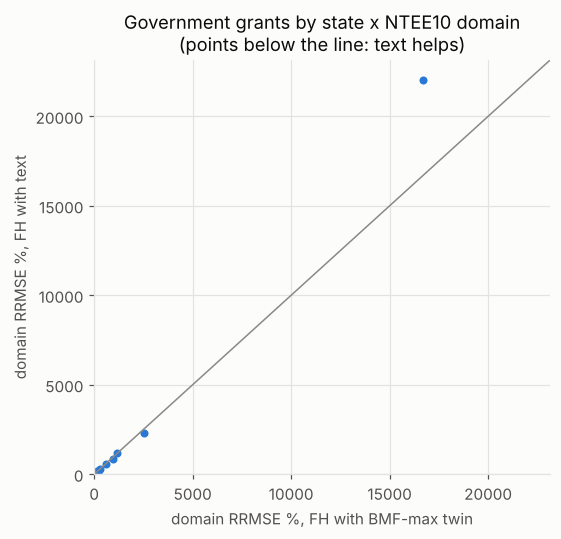

In [7]:
y = "y_gov_grants"
a = per[(per.y == y) & (per.estimator == "FH_text")].set_index("domain").rrmse_pct
b = per[(per.y == y) & (per.estimator == "FH_twin")].set_index("domain").rrmse_pct
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(b, a.reindex(b.index), s=18, color=plotstyle.SERIES[0])
lim = [0, max(b.max(), a.max()) * 1.05]; ax.plot(lim, lim, color=plotstyle.NEUTRAL, lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("domain RRMSE %, FH with BMF-max twin"); ax.set_ylabel("domain RRMSE %, FH with text")
ax.set_title("Government grants by state x NTEE10 domain\n(points below the line: text helps)")
plt.tight_layout(); plt.savefig(f"{RES}/sae_gov_grants_domains.png", dpi=150); plt.show()